# Triangle plots for subluminal chains, constant $c_s^2$, with CMB lensing and DES, without the quasi-static approximation (linear CMB lensing, preliminary)

In [1]:
import numpy as np
import getdist
from getdist import plots
from matplotlib.lines import Line2D

import utils

In [2]:
indices = [76, 84, 98, 99, 100, 101, 117, 118, 119, 120]
chains = {}
for i in indices:
    chains[i] = utils.load_chain(i, burn_in=0.6, smooth_2D=0.35, smooth_1D=0.35)
    # A few rows of the preliminary no-QSA chains have sigma8 = NaN; drop them
    chains[i].filter(np.isfinite(chains[i].samples).all(axis=1))

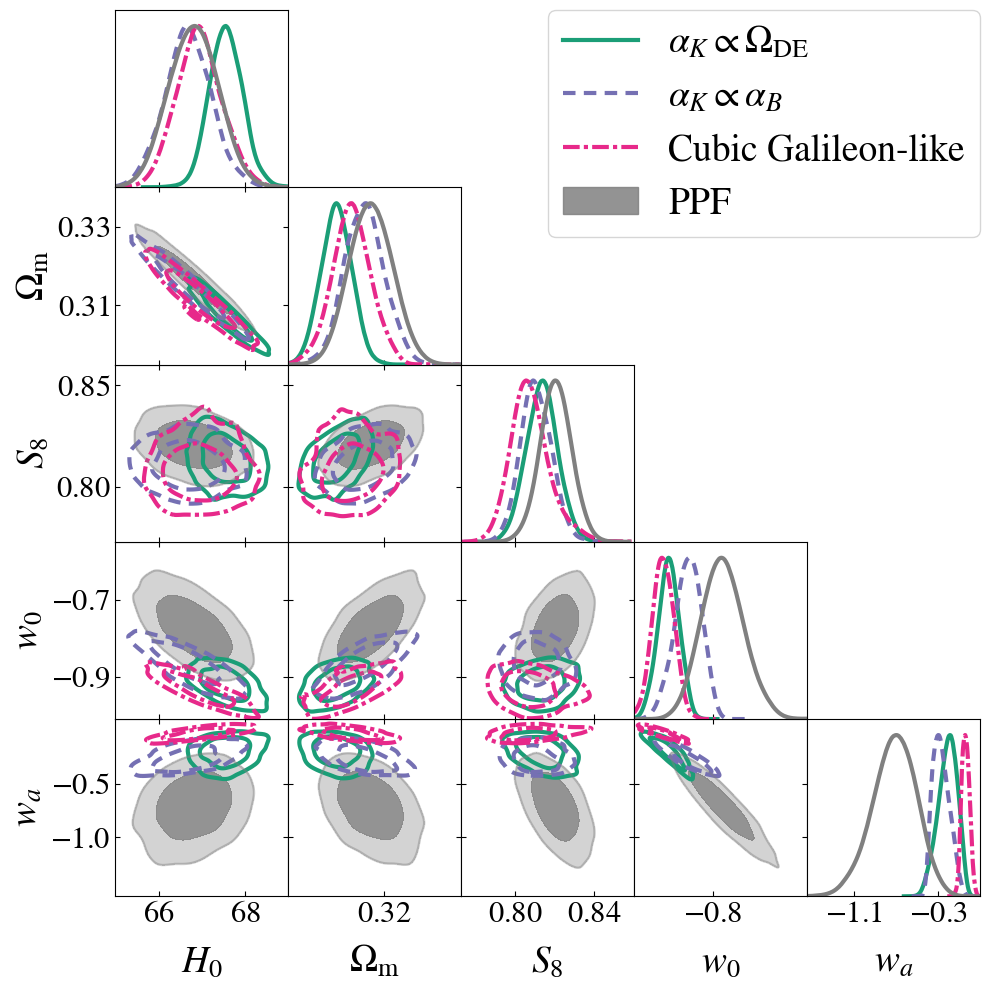

In [3]:
p = plots.get_subplot_plotter()
p.settings.axes_fontsize=25
p.settings.axes_labelsize=30
p.settings.legend_fontsize=22
p.triangle_plot(
    [chains[117], chains[119], chains[120], chains[76]],
    ["omegam", "S8", "w", "wa"],
    filled=[False, False, False, True],
    contour_colors=[utils.colors[0], utils.colors[2], utils.colors[3], "#b0b0b0"],
    contour_lws=2,
    contour_ls=["-", "-", "-", "-"],
    markers={"w": -1, "wa": 0},
    marker_args={"color": "black", "ls": "--", "lw": 1.2},
    legend_labels=["$\\alpha_K \\propto \\Omega_\\mathrm{DE}$", "$\\alpha_K \\propto \\alpha_B$", "Cubic Galileon-like", "PPF"],
    legend_loc="upper right",
    param_limits={"w": [-1.05, -0.55], "wa": [-1.55, 0.1], "H0": [65, 69], "omegam": [0.295, 0.34]}
)
p.fig.savefig("plots/triangle_ds2_subluminal_mg_noqsa.pdf", bbox_inches="tight")

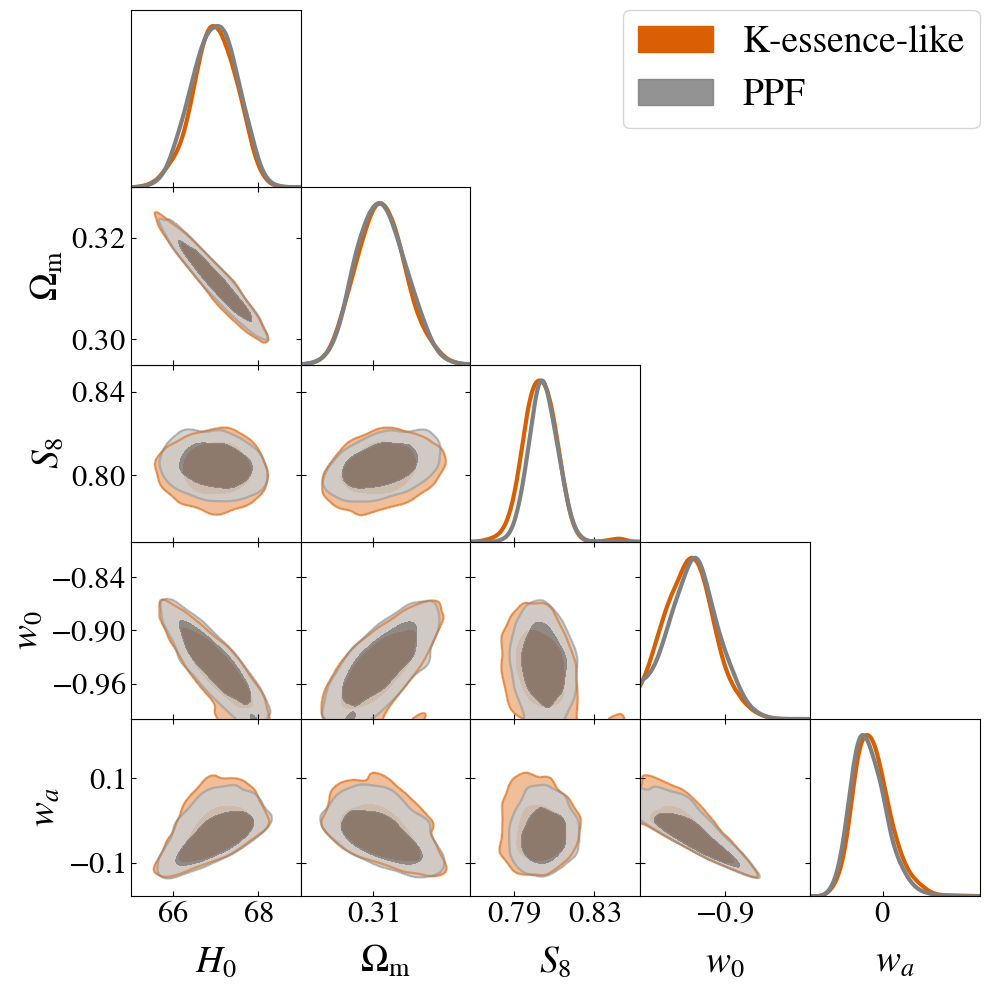

In [4]:
p = plots.get_subplot_plotter()
p.settings.axes_fontsize=25
p.settings.axes_labelsize=30
p.settings.legend_fontsize=30
p.triangle_plot(
    [chains[118], chains[84]],
    ["H0", "omegam", "S8", "w", "wa"],
    filled=[True, True],
    contour_colors=[utils.colors[1], "gray"],
    contour_lws=3,
    contour_ls='-',
    legend_labels=["K-essence-like", "PPF"],
    legend_loc="upper right",
    param_limits={"w": [-1, -0.8], "H0": [65, 69], "omegam": [0.295, 0.33]}
)
p.fig.savefig("plots/triangle_ds2_subluminal_mg_kessence_noqsa.pdf", bbox_inches="tight")

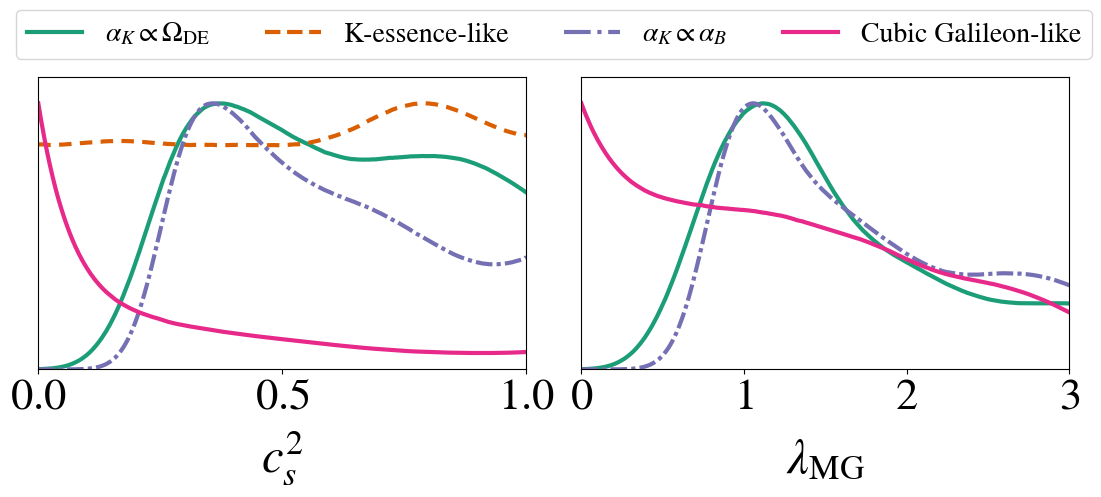

In [5]:
p = plots.get_subplot_plotter(width_inch=7, subplot_size_ratio=4/5)
p.settings.axes_fontsize=32
p.settings.axes_labelsize=35
p.settings.legend_fontsize=30
labels = ["$\\alpha_K \\propto \\Omega_\\mathrm{DE}$", "K-essence-like", "$\\alpha_K \\propto \\alpha_B$", "Cubic Galileon-like"]
p.plots_1d(
    [chains[117], chains[118], chains[119], chains[120]],
    ["cs2_0", "alpha_K_0"],
    colors=utils.colors,
    lws=3,
    ls=["-", "--", "-.", "-"],
    nx=1,
    legend_labels=[],
)

from matplotlib.lines import Line2D

handles = [
    Line2D([], [], linewidth=3, linestyle="-",  color=utils.colors[0]),
    Line2D([], [], linewidth=3, linestyle="--", color=utils.colors[1]),
    Line2D([], [], linewidth=3, linestyle="-.", color=utils.colors[2]),
    Line2D([], [], linewidth=3, linestyle="-",  color=utils.colors[3]),
]

# place legend relative to the figure (x,y in figure coordinates)
p.fig.legend(handles, labels,
             loc="lower center",
             ncol=2,
             fontsize=20,
             bbox_to_anchor=(0.508, 1.0),
             bbox_transform=p.fig.transFigure,
             frameon=True)

p.fig.savefig("plots/lambda_mg_cs2_subluminal_ds2_noqsa.pdf", bbox_inches="tight")

In [6]:
def latex_value(chain, param):
    if not chain.paramNames.hasParam(param): return "---"
    latex = chain.getInlineLatex(param)
    return f"${latex.split('=')[1]}$" if "=" in latex else f"${latex}$"

def print_table(columns, parameters):
    params = {name.name: label for name, label in zip(chains[117].paramNames.names, chains[117].paramNames.labels())}
    for param in parameters:
        print(f"${params[param]}$ & " + " & ".join(latex_value(chains[i], param) for i in columns) + r" \\ \hline")

In [7]:
# Getting numbers (same column order as the QSA table: PPF, Omega_DE, alpha_B, Cubic Galileon, K-essence, PPF w0waq)
print_table([76, 117, 119, 120, 118, 84], ["omegam", "H0", "S8", "w", "wa", "cs2_0", "alpha_K_0"])

$\Omega_\mathrm{m}$ & $ 0.3165\pm 0.0057$ & $ 0.3075\pm 0.0040$ & $ 0.3148^{+0.0048}_{-0.0056}$ & $ 0.3115\pm 0.0052$ & $ 0.3116\pm 0.0051$ & $ 0.3117^{+0.0048}_{-0.0057}$ \\ \hline
$H_0$ & $ 66.81\pm 0.57$ & $ 67.56\pm 0.39$ & $ 66.68\pm 0.55$ & $ 66.94\pm 0.54$ & $ 66.98^{+0.56}_{-0.49}$ & $ 66.97\pm 0.56$ \\ \hline
$S_8$ & $ 0.8206\pm 0.0081$ & $ 0.8136\pm 0.0080$ & $ 0.8107\pm 0.0080$ & $ 0.8078^{+0.0079}_{-0.011}$ & $ 0.8031\pm 0.0090$ & $ 0.8046\pm 0.0075$ \\ \hline
$w_0$ & $ -0.774^{+0.053}_{-0.061}$ & $ -0.918\pm 0.029$ & $ -0.867^{+0.040}_{-0.033}$ & $ -0.933\pm 0.030$ & $ -0.941^{+0.027}_{-0.032}$ & $ -0.937\pm 0.030$ \\ \hline
$w_a$ & $ -0.72^{+0.23}_{-0.19}$ & $ -0.209^{+0.11}_{-0.078}$ & $ -0.269^{+0.062}_{-0.099}$ & $ -0.038^{+0.035}_{-0.041}$ & $ -0.024^{+0.036}_{-0.053}$ & $ -0.033^{+0.036}_{-0.050}$ \\ \hline
$c_s^2$ & $ ---$ & $ 0.57\pm 0.23$ & $ 0.54^{+0.16}_{-0.29}$ & $c_s^2 < 0.355$ & $ ---$ & $ ---$ \\ \hline
$\lambda_\mathrm{MG}$ & --- & $ 1.46^{+0.39}_{-0.82}$ &

## Comparison with the QSA chains

QSA chains: 98-101, linear lensing, the exact QSA counterparts of 117-120. Dashed: QSA; solid: no QSA; gray: PPF.

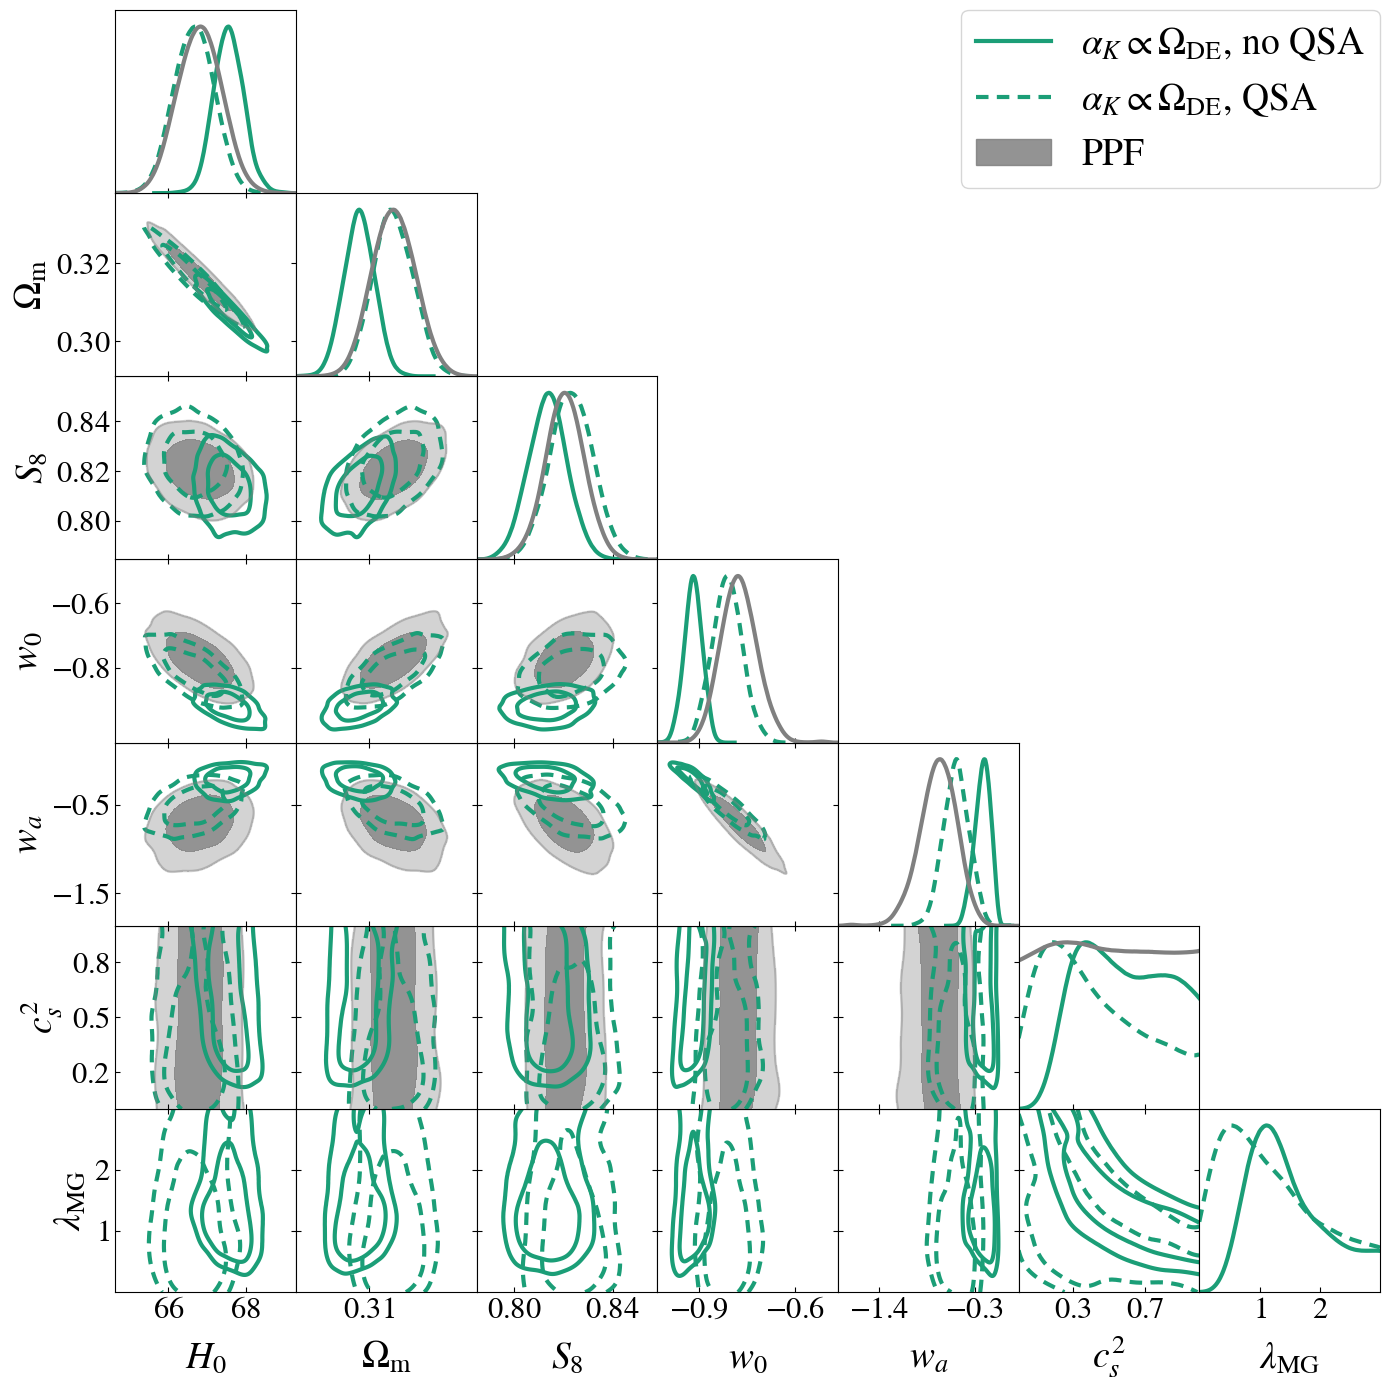

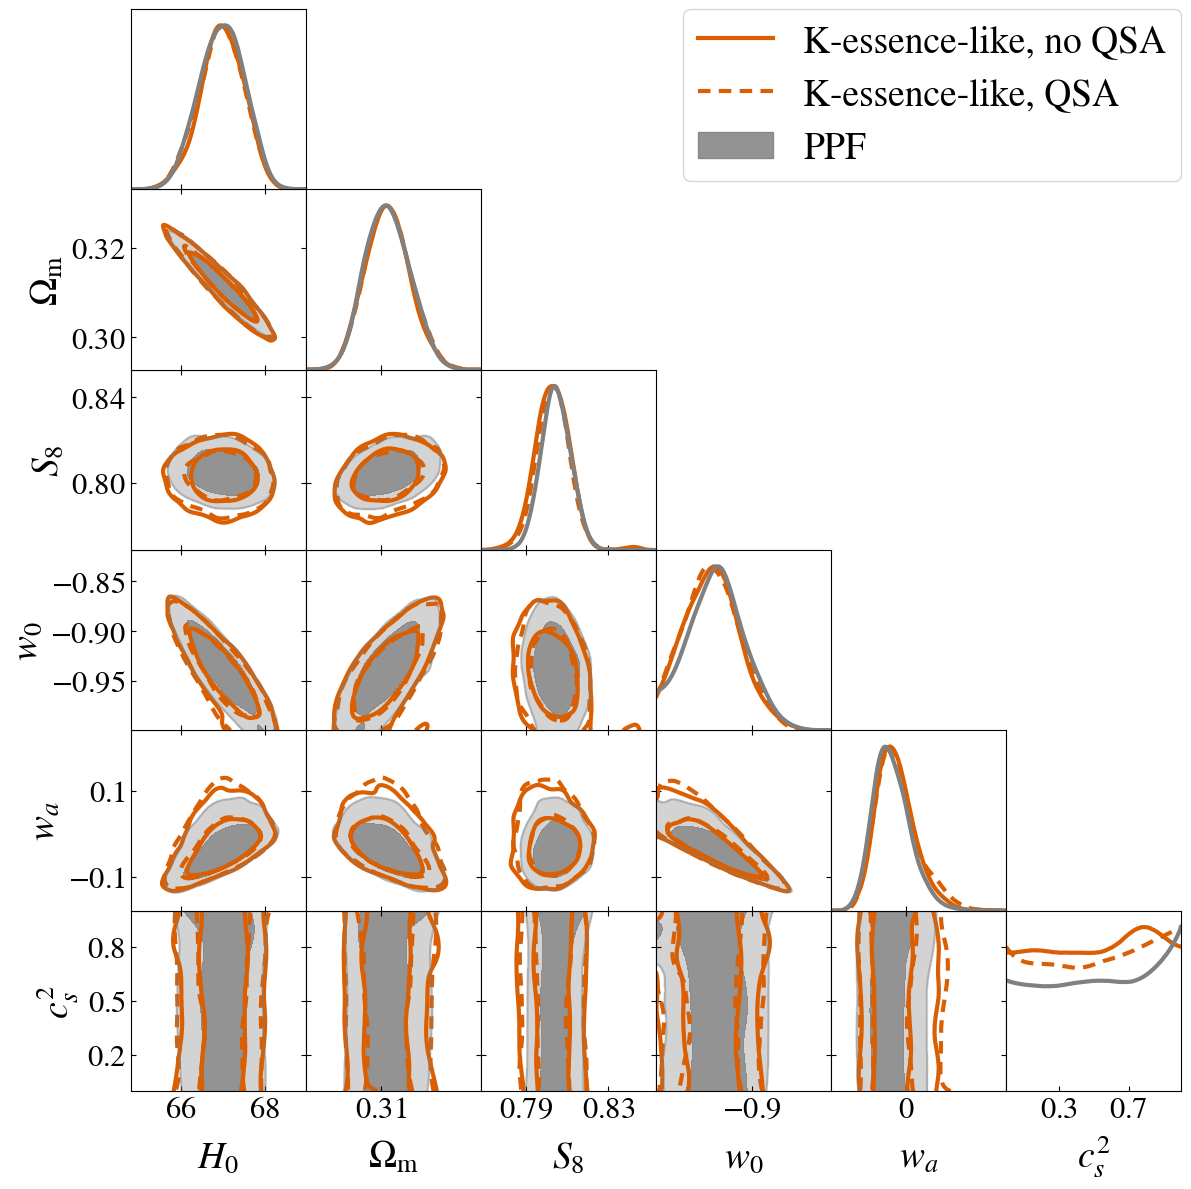

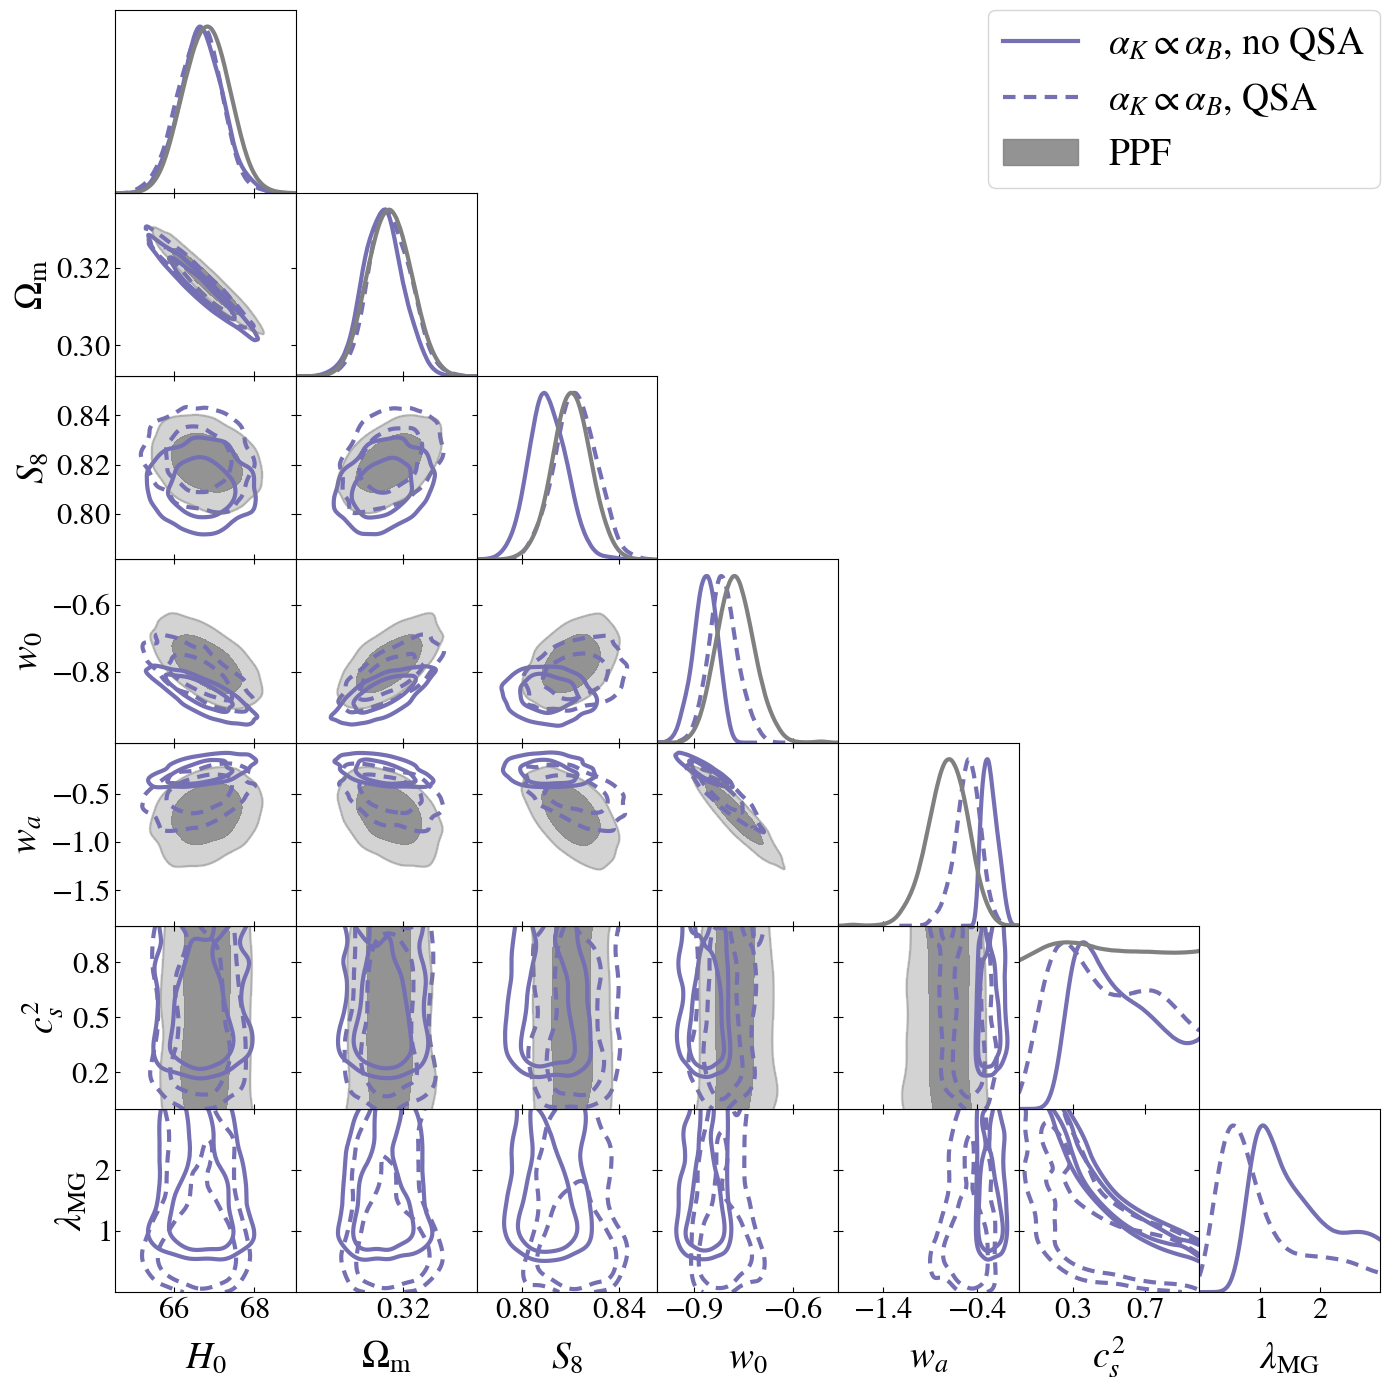

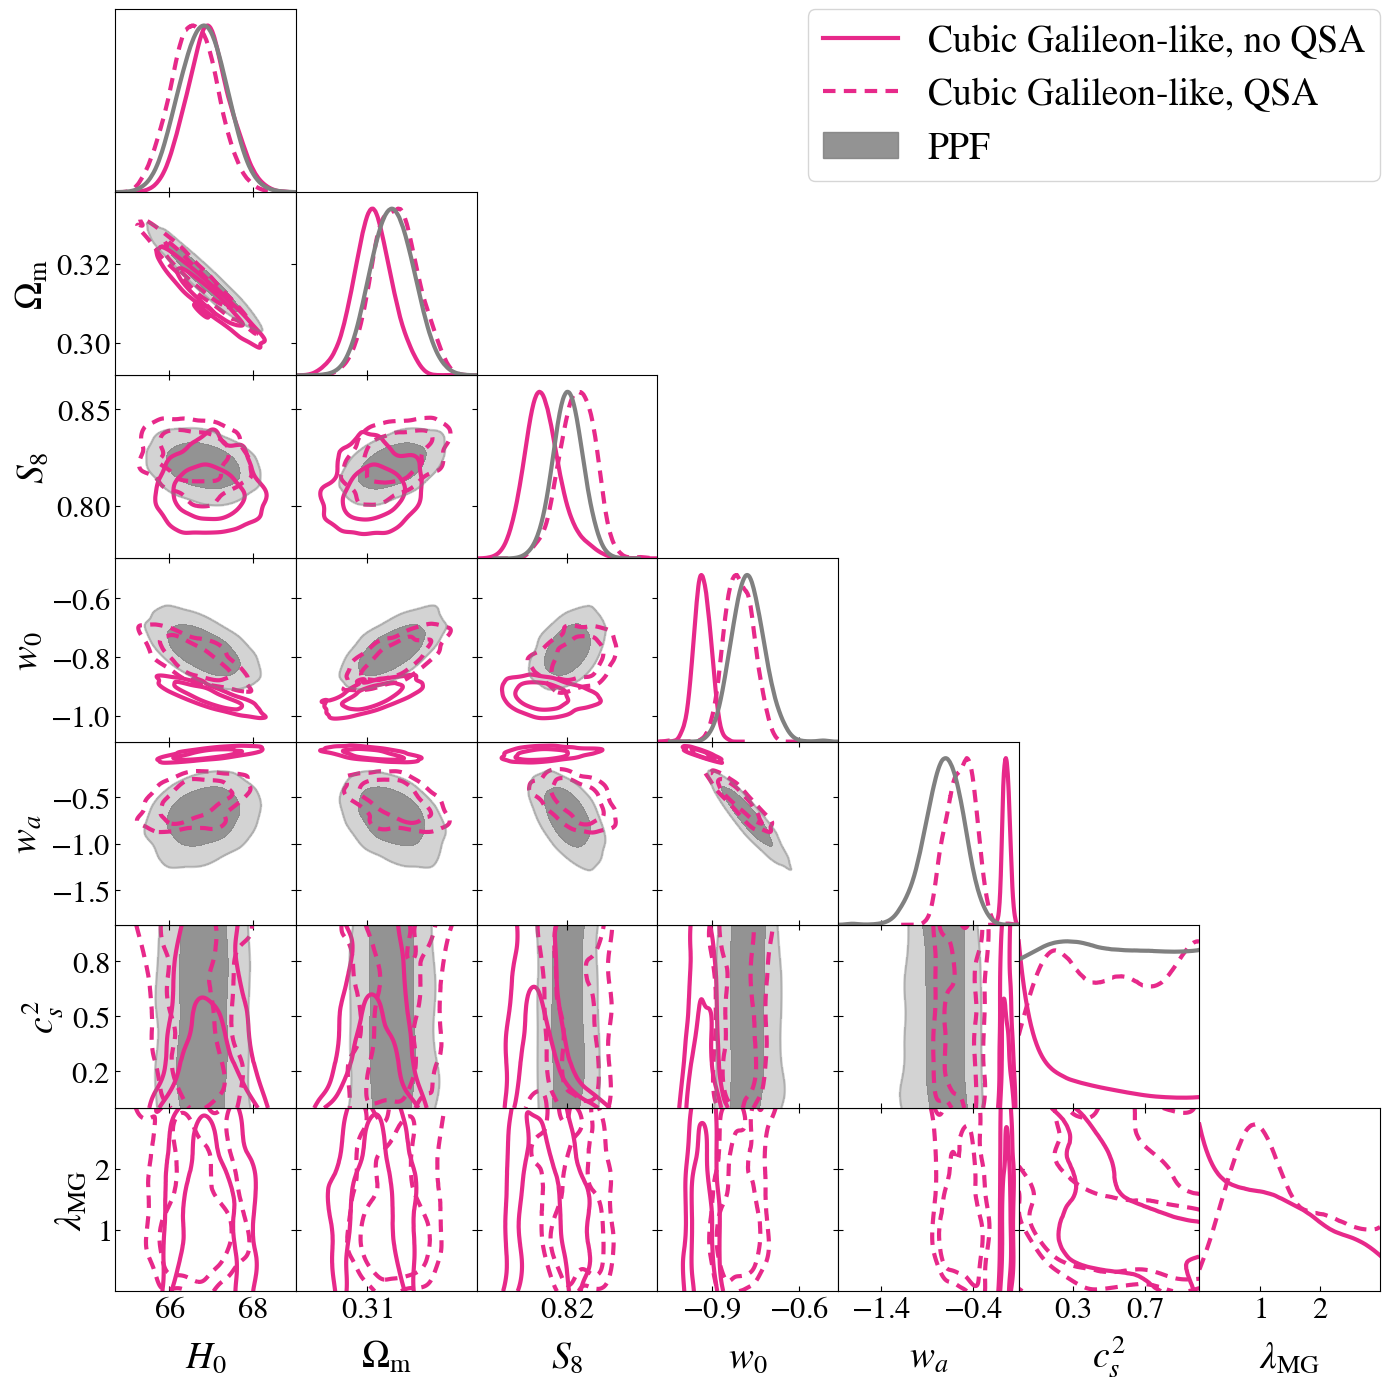

In [8]:
names = ["omega", "kessence", "prop", "cugal"]
noqsa_indices = [117, 118, 119, 120]
qsa_indices = [98, 99, 100, 101]
gr_indices = [76, 84, 76, 76]

for name, label, color, i_noqsa, i_qsa, i_gr in zip(names, labels, utils.colors, noqsa_indices, qsa_indices, gr_indices):
    params = ["H0", "omegam", "S8", "w", "wa", "cs2_0"]
    if chains[i_noqsa].paramNames.hasParam("alpha_K_0"): params.append("alpha_K_0")
    p = plots.get_subplot_plotter()
    p.settings.axes_fontsize=25
    p.settings.axes_labelsize=30
    p.settings.legend_fontsize=30
    p.triangle_plot(
        [chains[i_noqsa], chains[i_qsa], chains[i_gr]],
        params,
        filled=[False, False, True],
        contour_colors=[color, color, "gray"],
        contour_lws=3,
        contour_ls=["-", "--", "-"],
        legend_labels=[f"{label}, no QSA", f"{label}, QSA", "PPF"],
        legend_loc="upper right",
    )
    p.fig.savefig(f"plots/triangle_ds2_subluminal_qsa_vs_noqsa_{name}.pdf", bbox_inches="tight")

In [9]:
# Columns: for each model (Omega_DE, alpha_B, Cubic Galileon, K-essence), QSA then no QSA
columns = []
for i_qsa, i_noqsa in [(98, 117), (100, 119), (101, 120), (99, 118)]:
    columns += [i_qsa, i_noqsa]
print_table(columns, ["omegam", "H0", "S8", "w", "wa", "cs2_0", "alpha_K_0"])

$\Omega_\mathrm{m}$ & $ 0.3164\pm 0.0052$ & $ 0.3075\pm 0.0040$ & $ 0.3166\pm 0.0055$ & $ 0.3148^{+0.0048}_{-0.0056}$ & $ 0.3173^{+0.0054}_{-0.0061}$ & $ 0.3115\pm 0.0052$ & $ 0.3118^{+0.0048}_{-0.0056}$ & $ 0.3116\pm 0.0051$ \\ \hline
$H_0$ & $ 66.67\pm 0.52$ & $ 67.56\pm 0.39$ & $ 66.63\pm 0.55$ & $ 66.68\pm 0.55$ & $ 66.60\pm 0.56$ & $ 66.94\pm 0.54$ & $ 66.95^{+0.59}_{-0.49}$ & $ 66.98^{+0.56}_{-0.49}$ \\ \hline
$S_8$ & $ 0.8232\pm 0.0089$ & $ 0.8136\pm 0.0080$ & $ 0.8222\pm 0.0087$ & $ 0.8107\pm 0.0080$ & $ 0.826^{+0.010}_{-0.0085}$ & $ 0.8078^{+0.0079}_{-0.011}$ & $ 0.8031\pm 0.0079$ & $ 0.8031\pm 0.0090$ \\ \hline
$w_0$ & $ -0.812\pm 0.048$ & $ -0.918\pm 0.029$ & $ -0.811^{+0.041}_{-0.047}$ & $ -0.867^{+0.040}_{-0.033}$ & $ -0.805\pm 0.050$ & $ -0.933\pm 0.030$ & $ -0.941^{+0.027}_{-0.032}$ & $ -0.941^{+0.027}_{-0.032}$ \\ \hline
$w_a$ & $ -0.51\pm 0.15$ & $ -0.209^{+0.11}_{-0.078}$ & $ -0.50^{+0.15}_{-0.12}$ & $ -0.269^{+0.062}_{-0.099}$ & $ -0.53^{+0.17}_{-0.14}$ & $ -0.038^{+

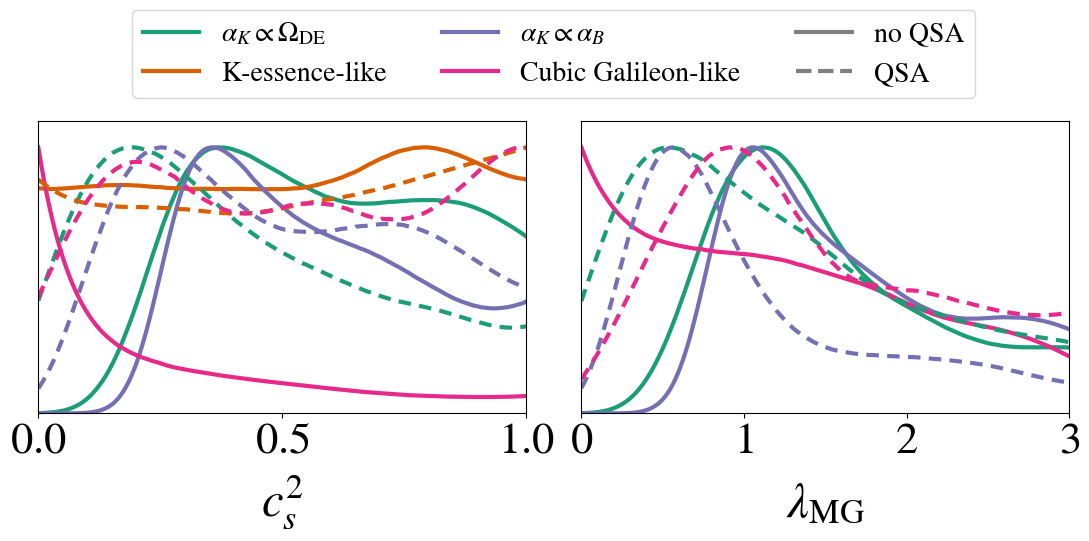

In [10]:
p = plots.get_subplot_plotter(width_inch=11, subplot_size_ratio=4/5)
p.settings.axes_fontsize=32
p.settings.axes_labelsize=35
p.plots_1d(
    [chains[i] for i in noqsa_indices] + [chains[i] for i in qsa_indices],
    ["cs2_0", "alpha_K_0"],
    colors=utils.colors[:4] + utils.colors[:4],
    lws=3,
    ls=["-"]*4 + ["--"]*4,
    nx=2,
    legend_labels=[],
)

handles = [Line2D([], [], linewidth=3, linestyle="-", color=color) for color in utils.colors[:4]]
handles += [Line2D([], [], linewidth=3, linestyle="-", color="gray"), Line2D([], [], linewidth=3, linestyle="--", color="gray")]
p.fig.legend(handles, labels + ["no QSA", "QSA"],
             loc="upper center",
             ncol=3,
             fontsize=20,
             bbox_to_anchor=(0.508, 1.25),
             bbox_transform=p.fig.transFigure,
             frameon=True)

p.fig.savefig("plots/lambda_mg_cs2_subluminal_ds2_qsa_vs_noqsa.pdf", bbox_inches="tight")

In [11]:
for i, chain in chains.items():
    try:
        print(i, chain.getGelmanRubin())
    except ValueError:
        print(i, "n/a (getdist could not compute R-1 after burn-in)")

76 n/a (getdist could not compute R-1 after burn-in)
84 n/a (getdist could not compute R-1 after burn-in)
98 n/a (getdist could not compute R-1 after burn-in)
99 n/a (getdist could not compute R-1 after burn-in)
100 n/a (getdist could not compute R-1 after burn-in)
101 n/a (getdist could not compute R-1 after burn-in)
117 n/a (getdist could not compute R-1 after burn-in)
118 n/a (getdist could not compute R-1 after burn-in)
119 n/a (getdist could not compute R-1 after burn-in)
120 n/a (getdist could not compute R-1 after burn-in)
